---
title: "Coordinates, Multiple Integrals and the Delta Function"
short_title: "M2 Coordinates & Integrals"
numbering:
  heading_2: true
  equation: true
---

# Coordinates, Integrals and the Delta Function

:::{tip} Where this sits in the plan
Math for **momentum** (center of mass, impulse), **angular momentum** (moments of inertia, polar coordinates) and **gravity and orbits** (conic sections).

| Item | Stewart | Boas | Zill | Arfken |
|---|---|---|---|---|
| Multiple integrals and Jacobians | 15 | 5 | 9 | 3 |
| Polar coordinates and conic sections | 10 | 5 | – | – |
| Cylindrical and spherical coordinates | 15 | 5, 6 | – | 3 |
| Dirac delta function | – | 7, 8 | 4 | 1 |

Chapter numbers are approximate, as in the workbook.
:::

Exercises have separate **hint** and **answer** dropdowns. Code cells that teach a technique are left visible.

::::{admonition} Pre-test: can you skip this notebook?
:class: dropdown

Work these without looking at the notes. Each problem names the section it tests. If **every part** is right, skip ahead to [Momentum and Collisions](../mechanics/02-momentum-collisions.ipynb). If you miss a part, study just the section it names and try that problem again.

1. **Multiple Integrals**

   (a) Evaluate $\iint xy\,dA$ over the triangle $0 \le y \le x \le 1$.

   (b) Write the same integral with the order of integration reversed (inner integral over $x$). Give the limits.

2. **Changing Variables: the Jacobian**

   (a) Find the Jacobian $|\partial(x, y)/\partial(u, v)|$ for $x = u + v$, $y = u - v$.

   (b) Use cylindrical coordinates to find the volume of a cone of height $h$ and base radius $R$.

   (c) Find the moment of inertia of a uniform solid cylinder (mass $M$, radius $R$) about its axis.

   (d) Find the center of mass of a thin uniform wire bent into a semicircle of radius $R$ (the arc only, $0 \le \phi \le \pi$).

3. **Polar Curves and Conic Sections**

   Take the orbit $r = p/(1 + e\cos\phi)$.

   (a) For $e = 0.5$ and $p = 3$, find $r_{\min}$, $r_{\max}$ and the semi-major axis $a$.

   (b) What kind of curve is $e = 2$? At what angles $\phi$ does $r \to \infty$?

4. **The Dirac Delta Function**

   (a) Evaluate $\int_{-\infty}^{\infty}\cos x\,\delta(x - \pi/3)\,dx$.

   (b) Evaluate $\int_0^{\infty}x^2\,\delta(x + 1)\,dx$.

   (c) Evaluate $\int_{-\infty}^{\infty}e^{-x}\,\delta(2x - 4)\,dx$.

   (d) Write $\delta(x^2 - a^2)$ (with $a > 0$) as a sum of delta functions of $x$.

   (e) A point mass $m$ sits at $x = a$ on a line. Write its linear mass density $\lambda(x)$. What are the units of $\delta(x)$?

:::{dropdown} Answers
1. (a) $\int_0^1 x\int_0^x y\,dy\,dx = \int_0^1\tfrac12x^3\,dx = \tfrac18$.

   (b) $\int_0^1\int_y^1 xy\,dx\,dy$.

2. (a) $|{-1} - 1| = 2$.

   (b) $\int_0^h\int_0^{2\pi}\int_0^{R(1 - z/h)}s\,ds\,d\phi\,dz = \tfrac13\pi R^2h$.

   (c) $\tfrac12MR^2$.

   (d) It sits on the symmetry axis at $y_{\text{cm}} = 2R/\pi$.

3. (a) $r_{\min} = p/(1 + e) = 2$, $r_{\max} = p/(1 - e) = 6$, and $a = 4$.

   (b) A hyperbola. $r \to \infty$ when $\cos\phi = -1/e = -\tfrac12$, so $\phi = \pm120^\circ$.

4. (a) $\tfrac12$.

   (b) $0$, because $x = -1$ is outside the range of integration.

   (c) $\delta(2x - 4) = \tfrac12\delta(x - 2)$, so the integral is $\tfrac12e^{-2}$.

   (d) $\dfrac{\delta(x - a) + \delta(x + a)}{2a}$.

   (e) $\lambda = m\,\delta(x - a)$. $\delta(x)$ has units of 1/length.
:::
::::

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from IPython.display import Math, display
from scipy.integrate import solve_ivp, quad

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (7, 4.6),
                     "axes.grid": True, "grid.alpha": 0.3})
g = 9.81  # m/s^2

## Multiple Integrals

A double integral $\iint_R f\,dA$ adds up $f$ times small areas. In Cartesian coordinates it is two ordinary integrals done one after the other, with the inner limits allowed to depend on the outer variable:

$$
\iint_R f\,dA = \int_a^b\!\!\int_{g_1(x)}^{g_2(x)} f(x,y)\,dy\,dx .
$$

Triple integrals work the same way with one more layer. In mechanics they compute three things over and over:

$$
M = \int\rho\,dV, \qquad \vec{R}_{\text{cm}} = \frac1M\int\vec{r}\,\rho\,dV, \qquad I = \int s^2\rho\,dV ,
$$

where $s$ is the distance from the rotation axis.

## Changing Variables: the Jacobian

If $x = x(u,v)$ and $y = y(u,v)$, a small rectangle $du\,dv$ in the $(u,v)$ plane maps to a small parallelogram whose area is $|J|\,du\,dv$, with

$$
J = \frac{\partial(x,y)}{\partial(u,v)} = \det\begin{pmatrix} x_u & x_v \\ y_u & y_v\end{pmatrix} .
$$ (eq-jacobian)

The same rule holds in three dimensions with a $3\times3$ determinant. The standard results:

| Coordinates | Volume (or area) element |
|---|---|
| Polar $(r,\phi)$ | $dA = r\,dr\,d\phi$ |
| Cylindrical $(\rho,\phi,z)$ | $dV = \rho\,d\rho\,d\phi\,dz$ |
| Spherical $(r,\theta,\phi)$ | $dV = r^2\sin\theta\,dr\,d\theta\,d\phi$ |

The factors are the products of the scale factors from the vectors-and-ODEs notes: a step $d\theta$ moves a point $r\,d\theta$, and a step $d\phi$ moves it $r\sin\theta\,d\phi$.

In [2]:
# Jacobians computed rather than memorized
r, th, ph = sp.symbols("r theta phi", positive=True)
polar = sp.Matrix([r * sp.cos(ph), r * sp.sin(ph)])
display(Math(r"\text{polar: } \det J = " + sp.latex(sp.simplify(polar.jacobian([r, ph]).det()))))
sph = sp.Matrix([r * sp.sin(th) * sp.cos(ph), r * sp.sin(th) * sp.sin(ph), r * sp.cos(th)])
display(Math(r"\text{spherical: } \det J = " + sp.latex(sp.simplify(sph.jacobian([r, th, ph]).det()))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

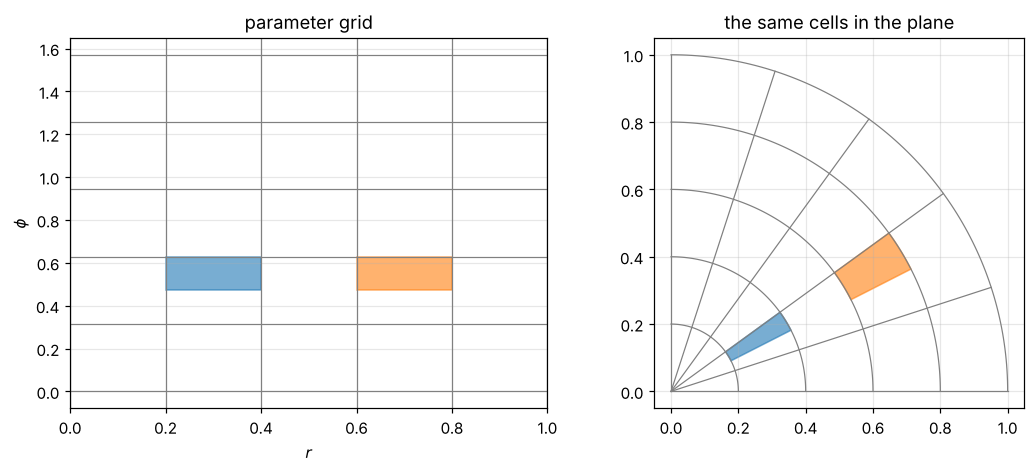

In [3]:
#| label: fig-jacobian
#| caption: A uniform grid in (r, φ) maps to cells whose area grows in proportion to r. That growth is the Jacobian factor r in dA = r dr dφ.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4))
for rr in np.linspace(0, 1, 6):
    axes[0].axvline(rr, color="gray", lw=0.8)
for pp in np.linspace(0, np.pi / 2, 6):
    axes[0].axhline(pp, color="gray", lw=0.8)
axes[0].add_patch(plt.Rectangle((0.6, 3 * np.pi / 20), 0.2, np.pi / 20, color="tab:orange", alpha=0.6))
axes[0].add_patch(plt.Rectangle((0.2, 3 * np.pi / 20), 0.2, np.pi / 20, color="tab:blue", alpha=0.6))
axes[0].set_xlabel("$r$"); axes[0].set_ylabel(r"$\phi$"); axes[0].set_title("parameter grid")

t = np.linspace(0, np.pi / 2, 100)
for rr in np.linspace(0, 1, 6):
    axes[1].plot(rr * np.cos(t), rr * np.sin(t), color="gray", lw=0.8)
for pp in np.linspace(0, np.pi / 2, 6):
    axes[1].plot([0, np.cos(pp)], [0, np.sin(pp)], color="gray", lw=0.8)
for (r0, c) in [(0.6, "tab:orange"), (0.2, "tab:blue")]:
    rs, ps = np.linspace(r0, r0 + 0.2, 20), np.linspace(3 * np.pi / 20, 4 * np.pi / 20, 20)
    edge = np.concatenate([np.c_[rs, np.full(20, ps[0])], np.c_[np.full(20, rs[-1]), ps],
                           np.c_[rs[::-1], np.full(20, ps[-1])], np.c_[np.full(20, rs[0]), ps[::-1]]])
    axes[1].fill(edge[:, 0] * np.cos(edge[:, 1]), edge[:, 0] * np.sin(edge[:, 1]), color=c, alpha=0.6)
axes[1].set_aspect("equal"); axes[1].set_title("the same cells in the plane")
plt.tight_layout(); plt.show()

::::{prf:example} Center of mass of a half-disk
:label: ex-half-disk

Find the center of mass of a uniform half-disk of radius $R$ occupying $y \ge 0$.

:::{dropdown} Solution
By symmetry $X = 0$. With surface density $\sigma$, $M = \tfrac12\pi R^2\sigma$ and

$$
Y = \frac1M\int_0^\pi\!\!\int_0^R (r\sin\phi)\,\sigma\,r\,dr\,d\phi = \frac{\sigma}{M}\cdot\frac{R^3}{3}\cdot 2 = \frac{4R}{3\pi} \approx 0.42R .
$$

The Jacobian $r$ matters here: without it the answer would be wrong by a factor that depends on $R$.
:::
::::

::::{prf:example} Moment of inertia of a uniform sphere
:label: ex-sphere-inertia

Find $I$ about a diameter for a solid sphere of mass $M$ and radius $R$.

:::{dropdown} Solution
The distance from the $z$-axis is $s = r\sin\theta$. With $\rho = 3M/(4\pi R^3)$,

$$
I = \rho\int_0^{2\pi}\!\!\int_0^\pi\!\!\int_0^R (r\sin\theta)^2\,r^2\sin\theta\,dr\,d\theta\,d\phi = \rho\cdot\frac{R^5}{5}\cdot\frac43\cdot2\pi = \frac25MR^2 .
$$
:::
::::

In [4]:
r, th, ph, R, M = sp.symbols("r theta phi R M", positive=True)
rho = 3 * M / (4 * sp.pi * R**3)
I = sp.integrate(rho * (r * sp.sin(th))**2 * r**2 * sp.sin(th), (r, 0, R), (th, 0, sp.pi), (ph, 0, 2 * sp.pi))
display(Math(r"I_{\text{sphere}} = " + sp.latex(sp.simplify(I))))

<IPython.core.display.Math object>

### Exercises

1. Find the moment of inertia of a uniform thin disk (mass $M$, radius $R$) about its symmetry axis.
2. Find the center of mass of a uniform solid hemisphere of radius $R$.
3. Use {eq}`eq-jacobian` to find the area element for elliptical coordinates $x = a r\cos\phi$, $y = b r\sin\phi$.

:::{dropdown} Hints
1. $s = r$ and $dA = r\,dr\,d\phi$.
2. Use spherical coordinates with $z = r\cos\theta$ and $0\le\theta\le\pi/2$.
3. It is the polar Jacobian with each column stretched.
:::

:::{dropdown} Answers
1. $I = \tfrac12MR^2$.
2. $Z = \tfrac38R$ above the flat face.
3. $dA = ab\,r\,dr\,d\phi$, so the area of the ellipse ($r\le1$) is $\pi ab$.
:::

## Polar Curves and Conic Sections

A curve in polar form is $r = r(\phi)$. The family that matters most in mechanics is

$$
r(\phi) = \frac{p}{1 + e\cos\phi} ,
$$ (eq-conic)

a **conic section** with one focus at the origin. The parameter $p$ (the *semi-latus rectum*) sets the size, and the **eccentricity** $e$ sets the shape:

| $e$ | Curve | Bounded? |
|---|---|---|
| $0$ | circle of radius $p$ | yes |
| $0 < e < 1$ | ellipse | yes |
| $1$ | parabola | no |
| $e > 1$ | one branch of a hyperbola | no |

For an ellipse, the closest and farthest distances from the focus are $r_{\min} = p/(1+e)$ and $r_{\max} = p/(1-e)$. Their average is the semi-major axis, and the semi-minor axis follows from it:

$$
a = \frac{p}{1 - e^2}, \qquad b = \frac{p}{\sqrt{1 - e^2}} = a\sqrt{1 - e^2} .
$$

**Why this form.** A conic is the set of points whose distance to the focus is $e$ times the distance to a fixed line (the directrix). Putting the focus at the origin and the directrix at $x = p/e$ gives $r = e(p/e - r\cos\phi)$, which rearranges to {eq}`eq-conic`. Orbits under inverse-square forces come out in exactly this form.

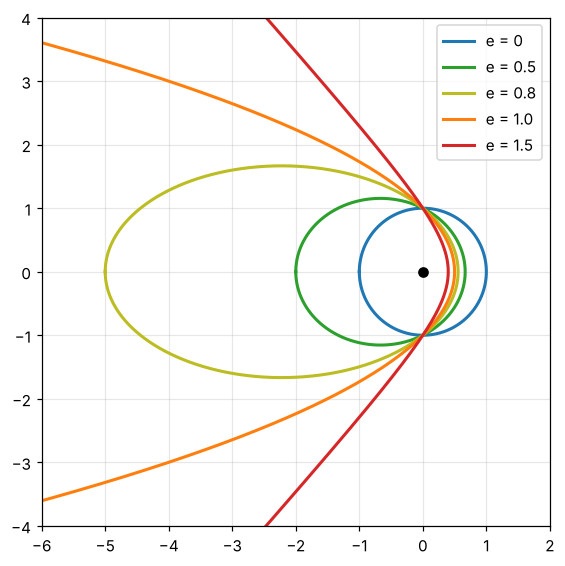

In [5]:
#| label: fig-conics
#| caption: The conic family r = p/(1 + e cos φ) with p = 1, all sharing a focus at the origin (black dot).
fig, ax = plt.subplots(figsize=(7, 6))
for e, c in [(0, "tab:blue"), (0.5, "tab:green"), (0.8, "tab:olive"), (1.0, "tab:orange"), (1.5, "tab:red")]:
    phi = np.linspace(-np.pi, np.pi, 4000)
    den = 1 + e * np.cos(phi)
    ok = den > 0.03
    r = np.where(ok, 1 / np.where(ok, den, 1), np.nan)
    ax.plot(r * np.cos(phi), r * np.sin(phi), color=c, lw=2, label=f"e = {e}")
ax.plot(0, 0, "ko")
ax.set_xlim(-6, 2); ax.set_ylim(-4, 4); ax.set_aspect("equal"); ax.legend()
plt.show()

### Exercises

1. An ellipse has $r_{\min} = 1$ and $r_{\max} = 3$. Find $e$, $p$ and $a$.
2. Show that $e = 0$ in {eq}`eq-conic` gives a circle, and convert $e = 1$ to Cartesian form.

:::{dropdown} Hints
1. Use $r_{\min} = p/(1+e)$ and $r_{\max} = p/(1-e)$.
2. For $e = 1$, write $r = p - r\cos\phi = p - x$ and square.
:::

:::{dropdown} Answers
1. $e = 0.5$, $p = 1.5$, $a = 2$.
2. $e = 0$ gives $r = p$. For $e = 1$, $x^2 + y^2 = (p - x)^2$, so $y^2 = p^2 - 2px$, a parabola opening to the left.
:::

## The Dirac Delta Function

A hammer blow, a point mass, a point charge: physics is full of quantities concentrated at a single point. The **delta function** describes them.

:::{prf:definition} Dirac delta
:label: def-delta

$\delta(x)$ is zero for $x\neq0$, and its integral over any interval containing $0$ is $1$. Its defining property is the **sifting property**:

$$
\int_{-\infty}^{\infty} f(x)\,\delta(x - a)\,dx = f(a) .
$$ (eq-sifting)
:::

No ordinary function has these properties. The delta is the limit of a sequence of ever narrower, taller spikes of unit area, for example Gaussians $\delta_\epsilon(x) = e^{-x^2/2\epsilon^2}/(\epsilon\sqrt{2\pi})$ as $\epsilon\to0$. Integrals involving $\delta$ mean the limit of the integrals.

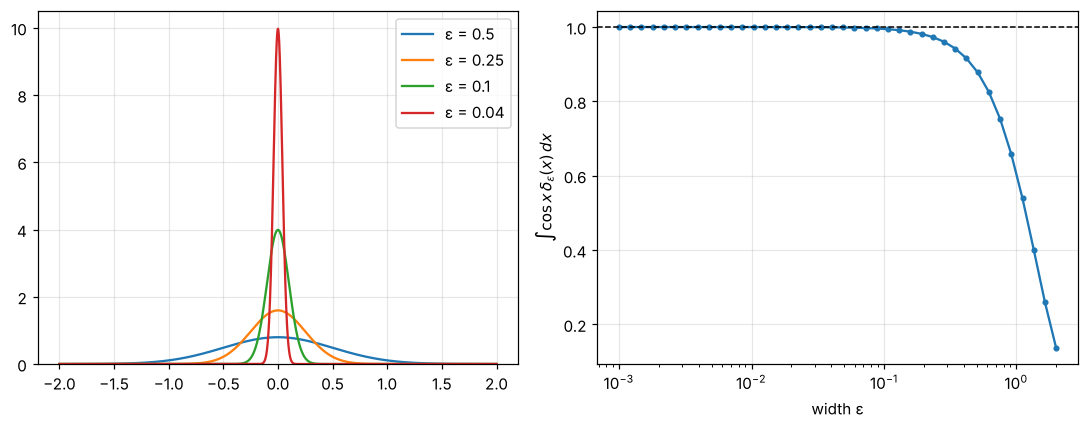

In [6]:
#| label: fig-delta
#| caption: Left, unit-area Gaussians narrowing toward δ(x). Right, the integral of f(x) = cos x against each one approaches f(0) = 1, which is the sifting property.
eps = [0.5, 0.25, 0.1, 0.04]
x = np.linspace(-2, 2, 2000)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for e in eps:
    axes[0].plot(x, np.exp(-x**2 / (2 * e**2)) / (e * np.sqrt(2 * np.pi)), label=f"ε = {e}")
axes[0].set_ylim(0, 10.5); axes[0].legend()
es = np.logspace(-3, 0.3, 40)
# integrate over ±12 widths so the solver cannot step over a very narrow spike
vals = [quad(lambda s: np.cos(s) * np.exp(-s**2 / (2 * e**2)) / (e * np.sqrt(2 * np.pi)), -12 * e, 12 * e)[0] for e in es]
axes[1].semilogx(es, vals, "o-", ms=3)
axes[1].axhline(1, color="k", ls="--", lw=1)
axes[1].set_xlabel("width ε"); axes[1].set_ylabel(r"$\int \cos x\,\delta_\varepsilon(x)\,dx$")
plt.tight_layout(); plt.show()

### Rules for working with the delta function

1. **Scaling:** $\delta(ax) = \dfrac{\delta(x)}{|a|}$.
2. **Composition:** if $g$ has simple roots $x_i$, then $\delta\big(g(x)\big) = \sum_i \dfrac{\delta(x - x_i)}{|g'(x_i)|}$.
3. **Step function:** the Heaviside step $\Theta(x)$ (0 for $x<0$, 1 for $x>0$) satisfies $\Theta'(x) = \delta(x)$.
4. **Three dimensions:** $\delta^3(\vec{r}) = \delta(x)\delta(y)\delta(z)$, so a point mass $m$ at $\vec{r}_0$ has density $\rho(\vec{r}) = m\,\delta^3(\vec{r} - \vec{r}_0)$.

**In mechanics.** An impulsive force $F(t) = J\,\delta(t - t_0)$ delivers momentum $J$ instantly: integrating $m\dot v = F$ across $t_0$ gives a jump $\Delta v = J/m$. In the momentum notes this models kicks and collisions, and in the oscillation notes it leads to Green's functions.

In [7]:
x, a = sp.symbols("x a", real=True)
display(Math(r"\int_{-\infty}^{\infty}\cos x\,\delta(x - a)\,dx = " + sp.latex(sp.integrate(sp.cos(x) * sp.DiracDelta(x - a), (x, -sp.oo, sp.oo)))))
display(Math(r"\int_{-\infty}^{\infty}e^x\,\delta(x^2 - 4)\,dx = " + sp.latex(sp.integrate(sp.exp(x) * sp.DiracDelta(x**2 - 4), (x, -sp.oo, sp.oo)))))
display(Math(r"\frac{d}{dx}\theta(x) = " + sp.latex(sp.diff(sp.Heaviside(x), x))))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exercises

1. Evaluate $\int_{-\infty}^\infty (x^2 + 1)\,\delta(3x - 6)\,dx$.
2. Evaluate $\int_{-\infty}^\infty e^{x}\,\delta(x^2 - 4)\,dx$ and compare with the code output.
3. A puck of mass $m$ at rest on frictionless ice receives a force $F(t) = J\,\delta(t - 1)$. Find $v(t)$.

:::{dropdown} Hints
1. Use the scaling rule with $a = 3$.
2. The roots are $\pm2$ and $|g'(\pm2)| = 4$.
3. Integrate $m\dot v = F$ from $0$ to $t$.
:::

:::{dropdown} Answers
1. $\tfrac13(2^2 + 1) = \tfrac53$.
2. $\tfrac14(e^2 + e^{-2}) = \tfrac12\cosh 2 \approx 1.88$.
3. $v(t) = (J/m)\,\Theta(t - 1)$: zero before $t = 1$, then constant.
:::

## Appendix: MyST patterns

Same conventions as the rest of the book: `prf:` directives for definitions, theorems and examples; `:::{dropdown}` for solutions, hints and answers; `$$ ... $$ (label)` with `` {eq}`label` `` for equations; and code cells tagged `hide-input` that start with `#| label:` and `#| caption:` lines.